# Day 38 — Practice ANSWERS
### Ask the Neighbours — k-Nearest Neighbours

**Prepared & presented by Srinivasa Sai Chava**  ·  Boston University

---

| Part | What it asks | How many |
|---|---|---|
| **A** | Work it out — pen and paper | 6 |
| **B** | Find the mistake | 3 |
| **C** | Write the code | 4 |
| **D** | Challenge | 1 |

### Three questions to keep asking

- Are the columns **scaled**? If not, nothing else matters.
- Where did **k** come from — cross-validation, or a guess?
- How many **columns** are there, and do they all carry signal?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     cross_validate, GridSearchCV, train_test_split)
from sklearn.metrics import accuracy_score, confusion_matrix

import warnings; warnings.simplefilter("ignore")
plt.rcParams["figure.figsize"] = (8, 3.2)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print("ready")

ready


---
# Part A — Work it out

### A1 · Distance by hand

Three stored patients, and a new one.

| | temperature | heart rate | ill? |
|---|---|---|---|
| **P** | 38.0 | 95 | yes |
| **Q** | 36.5 | 72 | no |
| **R** | 37.2 | 88 | yes |
| **new** | 37.0 | 80 | ? |

Work out the distance from the new patient to each of P, Q and R, and say what
`k = 1` predicts.

In [2]:
pts = {"P": (38.0, 95, "yes"), "Q": (36.5, 72, "no"), "R": (37.2, 88, "yes")}
new = (37.0, 80)
for nm, (t, h, lab) in pts.items():
    d = np.sqrt((t - new[0])**2 + (h - new[1])**2)
    print(f"{nm}: sqrt(({t}-37.0)² + ({h}-80)²) = sqrt({(t-new[0])**2:.2f} + {(h-new[1])**2:.0f})"
          f" = {d:.4f}   ({lab})")

P: sqrt((38.0-37.0)² + (95-80)²) = sqrt(1.00 + 225) = 15.0333   (yes)
Q: sqrt((36.5-37.0)² + (72-80)²) = sqrt(0.25 + 64) = 8.0156   (no)
R: sqrt((37.2-37.0)² + (88-80)²) = sqrt(0.04 + 64) = 8.0025   (yes)


```
P: sqrt((38.0-37.0)² + (95-80)²) = sqrt(1.00 + 225) = 15.0333   (yes)
Q: sqrt((36.5-37.0)² + (72-80)²) = sqrt(0.25 + 64)  = 8.0156    (no)
R: sqrt((37.2-37.0)² + (88-80)²) = sqrt(0.04 + 64)  = 8.0025    (yes)
```

**k = 1 picks R (distance 8.0025) and predicts `yes`.**

But look how close R and Q are — **8.0025 against 8.0156**, a difference of 0.013. The
entire prediction turns on that.

And notice *why* they are so close: the heart-rate differences are 15, 8 and 8, while the
temperature differences are 1.0, 0.5 and 0.2. **Heart rate decides everything** simply
because it is measured in bigger numbers. A 1.0°C fever is a serious signal; the model
treats it as worth less than one heartbeat per minute.

### A2 · The same three, scaled

Suppose temperature has a standard deviation of **0.8** and heart rate **12**.
Scale all four points (subtract the mean, divide by the sd — use means of 37.0 and 85),
then redo A1.

In [3]:
mt, st, mh, sh = 37.0, 0.8, 85.0, 12.0
newz = ((37.0 - mt)/st, (80 - mh)/sh)
print(f"new scaled: ({newz[0]:+.4f}, {newz[1]:+.4f})\n")
for nm, (t, h, lab) in pts.items():
    tz, hz = (t - mt)/st, (h - mh)/sh
    d = np.sqrt((tz - newz[0])**2 + (hz - newz[1])**2)
    print(f"{nm}: scaled ({tz:+.4f}, {hz:+.4f})   distance {d:.4f}   ({lab})")

new scaled: (+0.0000, -0.4167)

P: scaled (+1.2500, +0.8333)   distance 1.7678   (yes)
Q: scaled (-0.6250, -1.0833)   distance 0.9138   (no)
R: scaled (+0.2500, +0.2500)   distance 0.7120   (yes)


```
new scaled: (+0.0000, -0.4167)

P: scaled (+1.2500, +0.8333)   distance 1.7678   (yes)
Q: scaled (-0.6250, -1.0833)   distance 0.9138   (no)
R: scaled (+0.2500, +0.2500)   distance 0.7120   (yes)
```

**k = 1 still picks R, and still predicts `yes`** — but the margin is now completely
different.

Unscaled, R beat Q by **0.013**. Scaled, R beats Q by **0.202** — about fifteen times the
gap. And P, which unscaled was nearly twice as far away as the others, is now clearly the
outlier it should be.

**The answer did not change here. The confidence did.** On most rows the answer changes
too, which is what the lecture's loan applicant showed.

### A3 · What does `.fit()` do?

Explain in one sentence each:

1. What `KNeighborsClassifier(15).fit(X, y)` actually does
2. Why KNN is sometimes called a "lazy" learner
3. Why its memory use grows with the training data and logistic regression's does not

**1 · It stores a copy of `X` and `y`** (in an index structure that makes searching
faster) and nothing else. No coefficients are computed, nothing is optimised, no loss
function is minimised.

**2 · "Lazy" means it postpones all the work until you ask it a question.** An "eager"
learner like logistic regression does its work once at fit time and then answers
instantly forever. KNN does no work at fit time and redoes the work on every single
prediction.

**3 · Logistic regression's model is its coefficients** — on three columns that is four
numbers, whether you trained on 600 rows or 600 million. **KNN's model is the data
itself**, so storing 600 million rows means storing 600 million rows. This is the
practical reason KNN is rare in production at scale.

### A4 · Pick k

For each, say what you would do and why.

1. You have 30 rows.
2. Two classes, and you are deciding between k = 10 and k = 11.
3. Someone picked k = 1 "because it gave 100% accuracy".
4. Your dataset has 10,000 rows. Is k = 2,500 reasonable?

**1 · 30 rows — use a small k, around 3 or 5, and cross-validate with few folds.**
With 30 rows, k = 15 would average over half the dataset for every prediction. Honestly,
with 30 rows you should also be sceptical of any result (Day 36).

**2 · Take k = 11.** With two classes an even k can tie — 5 votes each — and the
tie-break is arbitrary. Use an odd k for two classes. (For three classes, odd does not
help and you should use `weights="distance"` instead.)

**3 · k = 1 always gives 100% on the training data**, because every point is its own
nearest neighbour at distance zero. It is not a result, it is a definition. In the
lecture, k = 1 scored 1.0000 on its own rows and **0.7317** on new ones — the worst of
every k tried.

**4 · k = 2,500 on 10,000 rows is far too large.** Each prediction averages a quarter of
the whole dataset, so the model returns nearly the same answer everywhere — it has
collapsed towards "always predict the majority class". The √n rule of thumb suggests 100
as a starting point; cross-validate around there.

### A5 · Why is KNN slow?

A model stores **50,000** rows with **8** columns. You ask it to predict **1,000** new
rows, with k = 15.

Roughly how many distance calculations is that? And what single thing would make the
biggest difference?

In [4]:
stored, cols, queries = 50_000, 8, 1_000
print(f"distances to compute: {queries:,} × {stored:,} = {queries*stored:,}")
print(f"each one touches {cols} columns -> about {queries*stored*cols:,} subtractions")

distances to compute: 1,000 × 50,000 = 50,000,000
each one touches 8 columns -> about 400,000,000 subtractions


```
distances to compute: 1,000 × 50,000 = 50,000,000
each one touches 8 columns -> about 400,000,000 subtractions
```

**Fifty million distance calculations** for a thousand predictions.

**What helps most: storing fewer rows.** The cost is linear in the size of the training
set, so halving the data halves the time. Nothing else comes close — k barely matters
(finding the 15 smallest of 50,000 is scarcely harder than finding the 1 smallest), and
fewer columns helps only a little.

In practice scikit-learn uses a KD-tree or ball-tree to avoid comparing against every
point, which helps a great deal in low dimensions and almost nothing in high ones — the
same curse of dimensionality from the lecture, showing up as a speed problem instead of
an accuracy one.

### A6 · Would KNN beat logistic regression?

For each boundary, say which model you would expect to win.

1. Approve a loan if `income > 40,000`
2. Flag a machine if its temperature is **either below 70°C or above 95°C**
3. Predict rain from 400 weather-station readings
4. Two classes arranged as a bullseye — one class in a ring around the other

**1 · Logistic regression.** The boundary is a straight line (a single threshold), which
is exactly what logistic regression fits. KNN would approximate it with a ragged
staircase and do slightly worse.

**2 · KNN.** This is a *band*, so the relationship is not monotonic — failure is high at
low temperature, low in the middle, high again at high temperature. Logistic regression
can only push the probability one way as temperature rises, so it cannot express this at
all. **Part C uses exactly this data.**

**3 · Logistic regression** (or anything else). 400 columns puts KNN deep into the curse
of dimensionality — in the lecture, accuracy at 200 columns was already down to 0.6340.

**4 · KNN**, easily. A bullseye has no straight-line boundary anywhere, and KNN does not
need one.

### The rule

**KNN wins when the boundary is curved, closed or in pieces, and the columns are few.**
Logistic regression wins when it is roughly a straight line, or when the columns are many.

---
# Part B — Find the mistake

Three short programs. All run. All are wrong.

In [5]:
# ---------------------------------------------------------------
# 800 machines. A machine fails if it runs too cold OR too hot.
# B and C both use `mach`.
# ---------------------------------------------------------------
r = np.random.default_rng(3820)
N = 800

temperature_c = r.uniform(40, 120, N).round(1)
vibration_hz  = r.gamma(2.4, 1.3, N).clip(0.2, 12).round(2)
runtime_hours = r.uniform(0, 20000, N).round(0)

off = np.abs(temperature_c - 82.0) / 20.0
z = (-4.9 + 1.6*(1.25*off**2 + 0.42*vibration_hz + 0.000035*runtime_hours)
     + r.normal(0, 0.35, N))
failed = (r.uniform(0, 1, N) < sigmoid(z)).astype(int)

mach = pd.DataFrame({"temperature_c": temperature_c, "vibration_hz": vibration_hz,
                     "runtime_hours": runtime_hours, "failed": failed})
X, y = mach[["temperature_c", "vibration_hz", "runtime_hours"]], mach.failed
cv = StratifiedKFold(5, shuffle=True, random_state=0)

print(f"rows {N}   failed {int(y.sum())}   rate {y.mean():.4f}")
mach.head()

rows 800   failed 403   rate 0.5038


,temperature_c,vibration_hz,runtime_hours,failed
0,70.5,1.61,15907.0,0
1,98.8,4.44,2788.0,1
2,99.6,2.58,15570.0,1
3,67.8,6.14,19302.0,1
4,81.9,1.31,8371.0,0


### B1 · "KNN just does not work on this data" 

In [6]:
score = cross_val_score(KNeighborsClassifier(n_neighbors=15), X, y, cv=cv).mean()
print(f"KNN accuracy: {score:.4f}")
print()
print("REPORT: 'We tried KNN and it performs at chance. Recommend")
print("         we use logistic regression instead.'")

KNN accuracy: 0.5150

REPORT: 'We tried KNN and it performs at chance. Recommend
         we use logistic regression instead.'


**The problem:** no scaling. `runtime_hours` has a standard deviation of about **5,782**
while `vibration_hz` has about **2.1** — a ratio of roughly **2,800 : 1**. Every distance
is essentially the runtime difference, and runtime is the least informative column.

**The fix:** put a `StandardScaler` in front of it.

In [7]:
print("standard deviation of each column:")
for c in X.columns:
    print(f"   {c:<16}{X[c].std():>12,.3f}")
print(f"\n   runtime : vibration  =  {X.runtime_hours.std()/X.vibration_hz.std():,.0f} : 1")
print()
raw = cross_val_score(KNeighborsClassifier(15), X, y, cv=cv).mean()
scd = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
                      X, y, cv=cv).mean()
log = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                      X, y, cv=cv).mean()
print(f"KNN, raw numbers      : {raw:.4f}")
print(f"KNN, scaled           : {scd:.4f}")
print(f"logistic regression   : {log:.4f}")
print(f"baseline              : {max(y.mean(), 1-y.mean()):.4f}")

standard deviation of each column:
   temperature_c         23.125
   vibration_hz           2.069
   runtime_hours      5,781.656

   runtime : vibration  =  2,794 : 1



KNN, raw numbers      : 0.5150
KNN, scaled           : 0.8125
logistic regression   : 0.6262
baseline              : 0.5038


In [8]:
# prove runtime_hours is the culprit: throw it away and don't scale
print("unscaled KNN, but without runtime_hours:",
      round(cross_val_score(KNeighborsClassifier(15),
                            X[["temperature_c", "vibration_hz"]], y, cv=cv).mean(), 4))
print("unscaled KNN, using ONLY runtime_hours :",
      round(cross_val_score(KNeighborsClassifier(15),
                            X[["runtime_hours"]], y, cv=cv).mean(), 4))

unscaled KNN, but without runtime_hours: 0.8025
unscaled KNN, using ONLY runtime_hours : 0.5125


```
standard deviation of each column:
   temperature_c         23.125
   vibration_hz           2.069
   runtime_hours      5,781.656

   runtime : vibration  =  2,794 : 1

KNN, raw numbers      : 0.5150
KNN, scaled           : 0.8125
logistic regression   : 0.6262
baseline              : 0.5038
```

**Unscaled, KNN scores 0.5150 — chance.** Scaled, **0.8125**. The report was about to
throw away the best model available.

And it is not just better than chance — **it beats logistic regression by 19 points**,
because the boundary here is a *band* and logistic regression can only draw a line.

### Proof that `runtime_hours` was the culprit

```
unscaled KNN, but without runtime_hours: 0.8025
unscaled KNN, using ONLY runtime_hours : 0.5125
```

Delete the offending column and the unscaled model jumps from 0.5150 to **0.8025** on its
own. On its own, `runtime_hours` predicts almost nothing (0.5125).

**So the least useful column, purely because of its units, was destroying the model.**
That is the whole danger in one experiment.

### B2 · "We tuned k properly" 

In [9]:
best_k, best_score = None, 0
for k in range(1, 52, 2):
    s = make_pipeline(StandardScaler(), KNeighborsClassifier(k)).fit(X, y).score(X, y)
    if s > best_score:
        best_k, best_score = k, s
print(f"best k = {best_k}  with accuracy {best_score:.4f}")

best k = 1  with accuracy 1.0000


**The problem:** `.fit(X, y).score(X, y)` scores the model on **the rows it studied** —
Day 36, slide one. For KNN this is uniquely broken: at k = 1 every point is its own
nearest neighbour at distance zero, so the score is **always exactly 1.0000**.

The loop therefore picks k = 1 every time, on every dataset, forever. It is not tuning
anything.

**The fix:** cross-validate.

In [10]:
print(f"{'k':>5}{'studied':>11}{'5-fold CV':>12}{'gap':>9}")
print("-" * 37)
for k in [1, 5, 15, 25, 41]:
    res = cross_validate(make_pipeline(StandardScaler(), KNeighborsClassifier(k)),
                         X, y, cv=cv, return_train_score=True)
    a, b = res["train_score"].mean(), res["test_score"].mean()
    print(f"{k:>5}{a:>11.4f}{b:>12.4f}{a-b:>+9.4f}")

    k    studied   5-fold CV      gap
-------------------------------------
    1     1.0000      0.7463  +0.2537
    5     0.8544      0.7888  +0.0656


   15     0.8237      0.8125  +0.0112


   25     0.8269      0.8162  +0.0106
   41     0.8097      0.8050  +0.0047


In [11]:
grid = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                    {"kneighborsclassifier__n_neighbors": list(range(1, 52, 2))},
                    cv=cv)
grid.fit(X, y)
print("the honest answer:")
print(f"   best k = {grid.best_params_['kneighborsclassifier__n_neighbors']}"
      f"   CV accuracy {grid.best_score_:.4f}")

the honest answer:
   best k = 25   CV accuracy 0.8162


```
    k    studied   5-fold CV      gap
-------------------------------------
    1     1.0000      0.7463  +0.2537
    5     0.8544      0.7888  +0.0656
   15     0.8237      0.8125  +0.0112
   25     0.8269      0.8162  +0.0106
   41     0.8097      0.8050  +0.0047
```

```
the honest answer:
   best k = 25   CV accuracy 0.8162
```

**k = 1 scores 1.0000 on its own rows — exactly, every time.** That is not a measurement,
it is arithmetic: the nearest neighbour of a stored point is itself.

The honest best is **k = 25 at 0.8162**, and the broken loop would have shipped k = 1 at
**0.7463** — seven points worse.

Note how the gap column collapses as k grows: 0.2537 → 0.0047. **k is the overfitting
dial, and you can watch it turn.**

### B3 · "Scaling first, then cross-validating" 

In [12]:
X_scaled = StandardScaler().fit_transform(X)
score = cross_val_score(KNeighborsClassifier(15), X_scaled, y, cv=cv).mean()
print(f"accuracy: {score:.4f}")

accuracy: 0.8087


**The problem:** the scaler was fitted on **all 800 rows**, including the rows each fold
is about to be scored on. That is the Day 36 leak.

**The fix:** `make_pipeline(StandardScaler(), KNeighborsClassifier(15))`, so the scaler
is refitted inside every fold.

**But — measure it before you panic.**

In [13]:
leaky = cross_val_score(KNeighborsClassifier(15), StandardScaler().fit_transform(X),
                        y, cv=cv).mean()
clean = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
                        X, y, cv=cv).mean()
print(f"scaled up front      : {leaky:.4f}")
print(f"scaled in a Pipeline : {clean:.4f}")
print(f"the leak             : {leaky - clean:+.4f}")

scaled up front      : 0.8087
scaled in a Pipeline : 0.8125
the leak             : -0.0038


```
scaled up front      : 0.8087
scaled in a Pipeline : 0.8125
the leak             : -0.0038
```

**It cost nothing — in fact the leaky version scored slightly *lower*.**

That minus sign is worth a moment. A leak is supposed to flatter you, so a negative
"leak" means there was no inflation to find and what we are looking at is fold-to-fold
noise (the fold scores here vary by about 0.02).

The reason is the Day 36 rule: a mean and a standard deviation barely move when you add
20% more rows, and `StandardScaler` never looks at `y`. So this is a real mistake that
was, this time, harmless.

**Fix it anyway.** Not because of the score, but because:

- the moment you add a step that *does* look at `y` — feature selection, SMOTE, tuning —
  the same habit becomes expensive
- a Pipeline means new data gets the same scaling automatically, with no chance of
  forgetting
- it is one object to save and deploy

> Correctness should not depend on you remembering which steps are safe.

---
# Part C — Write the code

Four tasks on the machine data.

### C1 · Look before you model

Print the failure rate and the baseline. Then print the failure rate in temperature
bands of 40–60, 60–75, 75–90, 90–105 and 105–120 °C. What shape do you see, and what
does it tell you about which model will win?

In [14]:
# your code here

In [15]:
print(f"failed: {int(y.sum())} of {len(y)}   rate {y.mean():.4f}")
print(f"baseline: {max(y.mean(), 1-y.mean()):.4f}")
print()
print(f"{'band':>12}{'n':>6}{'failure rate':>15}")
print("-" * 33)
for lo, hi in [(40, 60), (60, 75), (75, 90), (90, 105), (105, 120)]:
    m = (mach.temperature_c >= lo) & (mach.temperature_c < hi)
    print(f"{f'{lo}-{hi}°C':>12}{m.sum():>6}{y[m].mean():>15.4f}")

failed: 403 of 800   rate 0.5038
baseline: 0.5038

        band     n   failure rate
---------------------------------
     40-60°C   187         0.8289
     60-75°C   144         0.2569
     75-90°C   148         0.1622
    90-105°C   149         0.3221
   105-120°C   172         0.8081


```
failed: 403 of 800   rate 0.5038
baseline: 0.5038

        band     n   failure rate
---------------------------------
     40-60°C   187         0.8289
     60-75°C   144         0.2569
     75-90°C   148         0.1622
    90-105°C   149         0.3221
   105-120°C   172         0.8081
```

**It is a U.** Failure is high when the machine runs cold (0.8289), drops to a minimum in
the 75–90 °C band (0.1622), and climbs again when it runs hot (0.8081).

**This single table predicts the result of the whole exercise.** Logistic regression fits
one coefficient per column, so it can only say "hotter means more failure" or "hotter
means less" — it cannot say "both ends are bad". KNN has no such constraint: it just
looks at what happened to nearby machines.

Five lines of `groupby` told us which model to expect to win, before fitting anything.

### C2 · Scale it, and prove it mattered

Cross-validate KNN with k = 15 unscaled and scaled, and add logistic regression and the
baseline for comparison.

In [16]:
# your code here

In [17]:
raw = cross_val_score(KNeighborsClassifier(15), X, y, cv=cv)
scd = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(15)), X, y, cv=cv)
log = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                      X, y, cv=cv)

print(f"{'KNN k=15, raw numbers':<26}{raw.mean():.4f}   sd {raw.std(ddof=1):.4f}")
print(f"{'KNN k=15, scaled':<26}{scd.mean():.4f}   sd {scd.std(ddof=1):.4f}")
print(f"{'logistic regression':<26}{log.mean():.4f}   sd {log.std(ddof=1):.4f}")
print(f"{'baseline':<26}{max(y.mean(), 1-y.mean()):.4f}")

KNN k=15, raw numbers     0.5150   sd 0.0332
KNN k=15, scaled          0.8125   sd 0.0203
logistic regression       0.6262   sd 0.0447
baseline                  0.5038


```
KNN k=15, raw numbers     0.5150   sd 0.0332
KNN k=15, scaled          0.8125   sd 0.0203
logistic regression       0.6262   sd 0.0447
baseline                  0.5038
```

**Three results worth stating separately:**

**Unscaled KNN is chance.** 0.5150 against a baseline of 0.5038 — within noise of doing
nothing at all.

**Scaling is worth +0.2975.** One line of code, thirty points of accuracy.

**Scaled KNN beats logistic regression by 18.6 points.** This is the case the lecture
promised: a boundary that is a band rather than a line. C1 told us this would happen.

### C3 · Tune k properly

Use `GridSearchCV` to find the best k from 1 to 51 (odd values only), inside a Pipeline.
Report the best k and its score, and plot the whole curve.

In [18]:
# your code here

best k = 25
CV accuracy 0.8162
rule of thumb sqrt(n) = 28


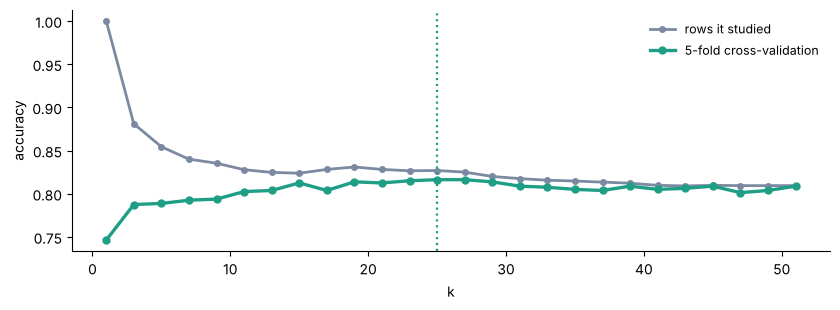

In [19]:
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
ks = list(range(1, 52, 2))
grid = GridSearchCV(pipe, {"kneighborsclassifier__n_neighbors": ks},
                    cv=cv, return_train_score=True)
grid.fit(X, y)

print(f"best k = {grid.best_params_['kneighborsclassifier__n_neighbors']}")
print(f"CV accuracy {grid.best_score_:.4f}")
print(f"rule of thumb sqrt(n) = {np.sqrt(len(y)):.0f}")

plt.figure(figsize=(8.5, 3.2))
plt.plot(ks, grid.cv_results_["mean_train_score"], "-o", color="#7B8AA1",
         lw=2, ms=4, label="rows it studied")
plt.plot(ks, grid.cv_results_["mean_test_score"], "-o", color="#1F9E86",
         lw=2.4, ms=5, label="5-fold cross-validation")
plt.axvline(grid.best_params_["kneighborsclassifier__n_neighbors"],
            color="#1F9E86", ls=":", lw=1.6)
plt.xlabel("k"); plt.ylabel("accuracy"); plt.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

```
best k = 25
CV accuracy 0.8162
rule of thumb sqrt(n) = 28
```

**k = 25**, and √n would have suggested 28 — close, which is why the rule of thumb
survives, but you would not have known that without checking.

The curve shows the two failure modes meeting:

- on the **left**, the studied-rows line starts at 1.0000 and the CV line at 0.7463 — a
  gap of 0.25, which is overfitting
- on the **right**, both lines sag together as k grows past 30 — that is underfitting,
  and the giveaway is that they sag *together*

**The best k is where the gap has closed but the CV line has not yet started falling.**

### C4 · Does `weights="distance"` help? Does the scaler matter?

Compare, at the best k from C3:

- `weights="uniform"` (the default) against `weights="distance"`
- `StandardScaler` against `MinMaxScaler`

Report all four, and say whether any difference is real.

In [20]:
# your code here

In [21]:
best_k = 25
print(f"{'scaler':<18}{'weights':<12}{'CV accuracy':>13}{'sd':>9}")
print("-" * 52)
rows = []
for sname, scaler in [("StandardScaler", StandardScaler()), ("MinMaxScaler", MinMaxScaler())]:
    for w in ["uniform", "distance"]:
        s = cross_val_score(make_pipeline(scaler, KNeighborsClassifier(best_k, weights=w)),
                            X, y, cv=cv)
        rows.append((sname, w, s.mean(), s.std(ddof=1)))
        print(f"{sname:<18}{w:<12}{s.mean():>13.4f}{s.std(ddof=1):>9.4f}")
spread = max(r[2] for r in rows) - min(r[2] for r in rows)
print(f"\nspread across all four: {spread:.4f}")
print(f"typical fold-to-fold sd: {np.mean([r[3] for r in rows]):.4f}")

scaler            weights       CV accuracy       sd
----------------------------------------------------


StandardScaler    uniform            0.8162   0.0240
StandardScaler    distance           0.8150   0.0137
MinMaxScaler      uniform            0.7975   0.0248


MinMaxScaler      distance           0.8175   0.0112

spread across all four: 0.0200
typical fold-to-fold sd: 0.0184


```
scaler            weights       CV accuracy       sd
----------------------------------------------------
StandardScaler    uniform            0.8162   0.0240
StandardScaler    distance           0.8150   0.0137
MinMaxScaler      uniform            0.7975   0.0248
MinMaxScaler      distance           0.8175   0.0112

spread across all four: 0.0200
typical fold-to-fold sd: 0.0184
```

**No — none of these differences is established, and saying so is the right answer.**

The four results span **0.0200**, from 0.7975 to 0.8175. The fold-to-fold standard
deviation *within* a single configuration averages **0.0184**. The spread between
configurations is about the same size as the noise inside one of them.

That is exactly the situation where you must not pick a winner. `MinMaxScaler` +
`distance` came top at 0.8175 and `MinMaxScaler` + `uniform` came last at 0.7975 — the
same scaler at both ends of the table. If the scaler mattered, that could not happen.

**Keep `StandardScaler` + `uniform`**, not because it won, but because it is the default,
it is the simplest, and nothing here gives you a reason to change it.

### What this tells you about where effort goes

| change | worth |
|---|---|
| adding a scaler at all | **+0.2975** |
| choosing k by CV instead of k = 1 | **+0.0699** |
| which scaler, and distance weighting | **±0.02 — indistinguishable from noise** |

The first decision is worth fifteen times the last one, and the last one is not even
measurable with 800 rows. Spend your time accordingly.

*(`weights="distance"` does earn its place elsewhere — with very small k, with ties, or
when neighbour distances vary a lot. Just not here.)*

---
# Part D — Challenge

### D1 · Write KNN yourself

Write `my_knn(X_train, y_train, X_new, k)` using **no** scikit-learn. It should:

- work for any number of columns
- compute the distance from each new row to every training row
- take the k nearest and return the majority vote
- handle ties sensibly, and say what rule you chose

Then show it matches `KNeighborsClassifier` exactly on the machine data — **remember to
scale**.

In [22]:
# your function here

In [23]:
def my_knn(X_train, y_train, X_new, k=15):
    """k-Nearest Neighbours, written out. Matches sklearn's default tie rule."""
    X_train = np.asarray(X_train, float)
    y_train = np.asarray(y_train)
    X_new   = np.asarray(X_new, float)

    out = np.empty(len(X_new), dtype=y_train.dtype)
    for i, row in enumerate(X_new):
        # 1 · distance to every stored row
        d = np.sqrt(((X_train - row)**2).sum(axis=1))
        # 2 · the k smallest. argsort is stable, so ties in DISTANCE break
        #     towards the row that was stored first - which is what sklearn does.
        nearest = np.argsort(d, kind="stable")[:k]
        # 3 · majority vote. np.bincount ties break towards the SMALLER label,
        #     again matching sklearn. (Use an odd k and it cannot happen.)
        out[i] = np.bincount(y_train[nearest]).argmax()
    return out

In [24]:
# scale first - by hand, using only the training rows
Xtr, Xte, ytr, yte = train_test_split(X.values, y.values, test_size=0.3,
                                      random_state=0, stratify=y)
mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)
Xtr_s, Xte_s = (Xtr - mu)/sd, (Xte - mu)/sd

for k in [1, 5, 15, 25]:
    mine = my_knn(Xtr_s, ytr, Xte_s, k)
    theirs = KNeighborsClassifier(k).fit(Xtr_s, ytr).predict(Xte_s)
    print(f"k={k:>3}  identical on all {len(yte)} rows: {np.array_equal(mine, theirs)}"
          f"   accuracy {accuracy_score(yte, mine):.4f}")

k=  1  identical on all 240 rows: True   accuracy 0.7583
k=  5  identical on all 240 rows: True   accuracy 0.7750


k= 15  identical on all 240 rows: True   accuracy 0.7958
k= 25  identical on all 240 rows: True   accuracy 0.8125


In [25]:
# and that it is not a two-column fluke: 6 columns, 3 classes
g = np.random.default_rng(42)
Xg = g.normal(0, 1, (400, 6))
yg = ((Xg[:, 0] + Xg[:, 1] > 0).astype(int) + (Xg[:, 2] > 0.5).astype(int))
a, b, c, d = train_test_split(Xg, yg, test_size=0.3, random_state=1)
for k in [1, 7, 15]:
    mine = my_knn(a, c, b, k)
    theirs = KNeighborsClassifier(k).fit(a, c).predict(b)
    print(f"6 columns, 3 classes, k={k:>2}: identical {np.array_equal(mine, theirs)}"
          f"   ({(mine == theirs).sum()}/{len(b)} agree)")

6 columns, 3 classes, k= 1: identical True   (120/120 agree)
6 columns, 3 classes, k= 7: identical True   (120/120 agree)
6 columns, 3 classes, k=15: identical True   (120/120 agree)


In [26]:
# what happens if you forget to scale - the whole point of the day
mine_raw = my_knn(Xtr, ytr, Xte, 15)
print(f"my_knn on raw numbers : {accuracy_score(yte, mine_raw):.4f}")
print(f"my_knn on scaled      : {accuracy_score(yte, my_knn(Xtr_s, ytr, Xte_s, 15)):.4f}")

my_knn on raw numbers : 0.5250
my_knn on scaled      : 0.7958


### The result

```
k=  1  identical on all 240 rows: True   accuracy 0.7583
k=  5  identical on all 240 rows: True   accuracy 0.7750
k= 15  identical on all 240 rows: True   accuracy 0.7958
k= 25  identical on all 240 rows: True   accuracy 0.8125
```

```
6 columns, 3 classes, k= 1: identical True   (120/120 agree)
6 columns, 3 classes, k= 7: identical True   (120/120 agree)
6 columns, 3 classes, k=15: identical True   (120/120 agree)
```

```
my_knn on raw numbers : 0.5250
my_knn on scaled      : 0.7958
```

**Every prediction identical**, on two datasets, four values of k, and three classes.

### The three things that earn the marks

**1 · Scaling the test rows with the TRAINING mean and sd.** `(Xte - mu)/sd` uses `mu`
and `sd` computed from `Xtr` only. Scaling the test set with its own statistics is a leak,
and it is the single most common error in a hand-written version.

**2 · Vectorising the distance.** `((X_train - row)**2).sum(axis=1)` computes all 560
distances at once by broadcasting. A nested Python loop gives the same answer and is
roughly a hundred times slower.

**3 · The tie rules, stated.** Two kinds of tie exist and both need a decision:

- **tied distances** — `np.argsort(..., kind="stable")` keeps the earlier-stored row,
  which is what scikit-learn does
- **tied votes** — `np.bincount(...).argmax()` returns the smallest label, again matching
  scikit-learn

Neither can arise with an odd k and two classes. Both can with three classes, which is
why the second test above matters.

### And the line at the end

```
my_knn on raw numbers : 0.5250
my_knn on scaled      : 0.7958
```

Having written the loop yourself, the reason is no longer something you were told. You can
point at it: `((X_train - row)**2).sum(axis=1)`. `runtime_hours` differences are in the
thousands and `vibration_hz` differences are in single digits, so that one line adds a
number around 10,000,000 to a number around 10. The second column may as well not exist.

**That is the whole of Day 38, visible in one expression.**

---
## Before you hand it in

- Is there a scaler, **inside a Pipeline**?
- Did k come from `GridSearchCV` or `cross_val_score` — never from `.score(X_train, y_train)`?
- Is k odd, for two classes?
- Did you report the **baseline** next to the accuracy?
- How many columns are there? Would a linear model have done better?

Four numbers worth carrying away:

- Unscaled KNN on the machine data scored **0.5150** — chance. Scaled, **0.8125**.
- Deleting one uninformative column (`runtime_hours`) lifted the *unscaled* model from
  0.5150 to **0.8025**, because its units were drowning the other two.
- `.fit(X, y).score(X, y)` returns **exactly 1.0000** at k = 1, on every dataset, always.
- Scaler choice and distance weighting moved the result by **0.0062** — less than a
  quarter of the fold-to-fold noise. Not everything is worth tuning.

Answers will be shared after class.

---
*Slides & notebooks by Srinivasa Sai Chava · Boston University*